# TA-05: Implementasi Decision Tree untuk Klasifikasi Titanic

## Exploratory Data Analysis (EDA) dan Preprocessing

**Studi Kasus:** Klasifikasi Kelangsungan Hidup Penumpang Titanic

**Algoritma:** Decision Tree Classifier

### Tujuan
Menganalisis dataset Titanic untuk memahami karakteristik data, distribusi variabel target, hubungan antara fitur dengan target, serta mengidentifikasi nilai yang hilang sebelum membangun model klasifikasi.

In [1]:
#cell 2 import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Pengaturan tampilan
pd.set_option('display.max_columns', None)
sns.set_theme(style="whitegrid")

print("Semua library berhasil diimpor.")

Semua library berhasil diimpor.


In [2]:
#cell 3 Memuat dataset
# Memuat dataset Titanic
df = pd.read_csv("../data/train.csv")
df_test = pd.read_csv("../data/test.csv")
df_submission = pd.read_csv("../data/gender_submission.csv")

print("Dataset berhasil dimuat.")

print("Train Dataset :", df.shape)
print("Test Dataset  :", df_test.shape)
print("Submission    :", df_submission.shape)

Dataset berhasil dimuat.
Train Dataset : (891, 12)
Test Dataset  : (418, 11)
Submission    : (418, 2)


In [3]:
#cell 4 Menampilkan beberapa baris pertama dari dataset
print("Lima Data Pertama Dataset Titanic:")
display(df.head())

Lima Data Pertama Dataset Titanic:


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [4]:
#cell 5 Menampilkan informasi dataset
print("Informasi Dataset:")
df.info()

Informasi Dataset:
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [5]:
#cell 6 Menampilkan statistik deskriptif dataset
print("Statistik Deskriptif Dataset:")
display(df.describe())

Statistik Deskriptif Dataset:


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [6]:
#Cell 7 — Memeriksa missing values
missing_values = pd.DataFrame({
    'Jumlah Missing Values': df.isnull().sum(),
    'Persentase Missing (%)': (df.isnull().sum() / len(df)) * 100
})

display(missing_values.sort_values(
    by='Jumlah Missing Values',
    ascending=False
))

,Jumlah Missing Values,Persentase Missing (%)
Cabin,687,77.104377
Age,177,19.865320
Embarked,2,0.224467
PassengerId,0,0.000000
Name,0,0.000000
Pclass,0,0.000000
Survived,0,0.000000
Sex,0,0.000000
Parch,0,0.000000
SibSp,0,0.000000


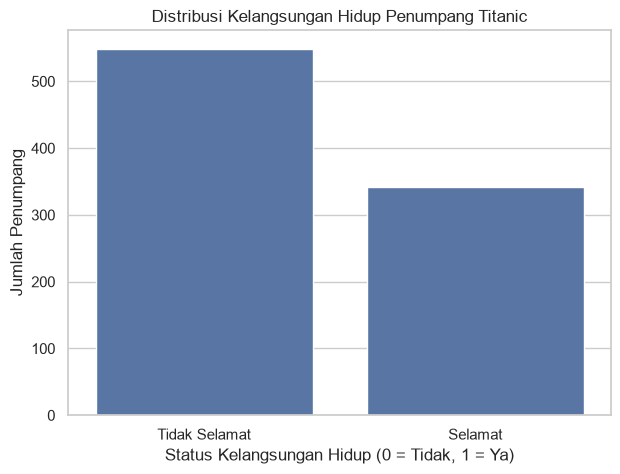


Jumlah masing-masing kelas:
Survived
0    549
1    342
Name: count, dtype: int64

Persentase masing-masing kelas:
Survived
0    61.616162
1    38.383838
Name: proportion, dtype: float64


In [7]:
#Cell 8 — Distribusi variabel target
plt.figure(figsize=(7, 5))

sns.countplot(
    x='Survived',
    data=df
)

plt.title('Distribusi Kelangsungan Hidup Penumpang Titanic')
plt.xlabel('Status Kelangsungan Hidup (0 = Tidak, 1 = Ya)')
plt.ylabel('Jumlah Penumpang')

plt.xticks([0, 1], ['Tidak Selamat', 'Selamat'])

plt.show()

print("\nJumlah masing-masing kelas:")
print(df['Survived'].value_counts())

print("\nPersentase masing-masing kelas:")
print(df['Survived'].value_counts(normalize=True) * 100)

=== Jenis Kelamin vs Kelangsungan Hidup ===


,Tidak Selamat,Selamat,Total
Sex,,,
female,81,233,314
male,468,109,577
All,549,342,891


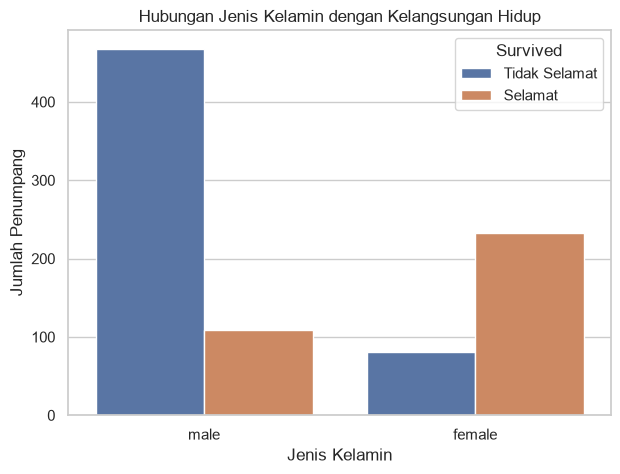

In [12]:
# Tabel jumlah penumpang berdasarkan jenis kelamin
print("=== Jenis Kelamin vs Kelangsungan Hidup ===")

sex_table = pd.crosstab(
    df['Sex'],
    df['Survived'],
    margins=True
)

sex_table.columns = ['Tidak Selamat', 'Selamat', 'Total']
display(sex_table)

# Visualisasi
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x='Sex',
    hue='Survived'
)

plt.title('Hubungan Jenis Kelamin dengan Kelangsungan Hidup')
plt.xlabel('Jenis Kelamin')
plt.ylabel('Jumlah Penumpang')
plt.legend(title='Survived', labels=['Tidak Selamat', 'Selamat'])

plt.show()

=== Kelas Tiket vs Kelangsungan Hidup ===


,Tidak Selamat,Selamat,Total
Pclass,,,
1,80,136,216
2,97,87,184
3,372,119,491
All,549,342,891


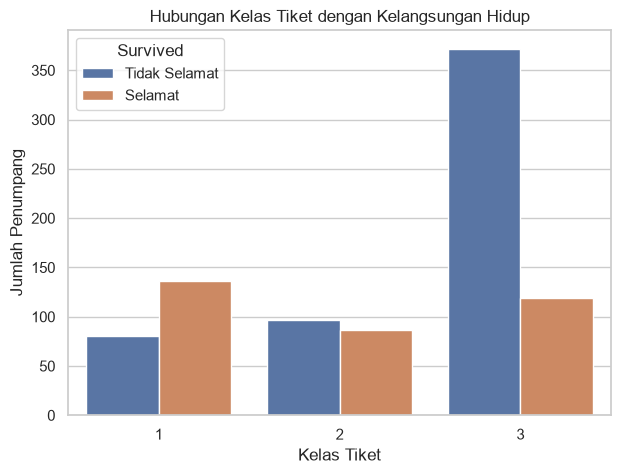

In [13]:
#Cell 10 — Hubungan kelas tiket dengan kelangsungan hidup
print("=== Kelas Tiket vs Kelangsungan Hidup ===")

pclass_table = pd.crosstab(
    df['Pclass'],
    df['Survived'],
    margins=True
)

pclass_table.columns = ['Tidak Selamat', 'Selamat', 'Total']
display(pclass_table)

# Visualisasi
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x='Pclass',
    hue='Survived'
)

plt.title('Hubungan Kelas Tiket dengan Kelangsungan Hidup')
plt.xlabel('Kelas Tiket')
plt.ylabel('Jumlah Penumpang')
plt.legend(title='Survived', labels=['Tidak Selamat', 'Selamat'])

plt.show()

=== Statistik Umur Berdasarkan Kelangsungan Hidup ===


,count,mean,median,min,max
Tidak Selamat,424,30.63,28.0,1.00,74.0
Selamat,290,28.34,28.0,0.42,80.0


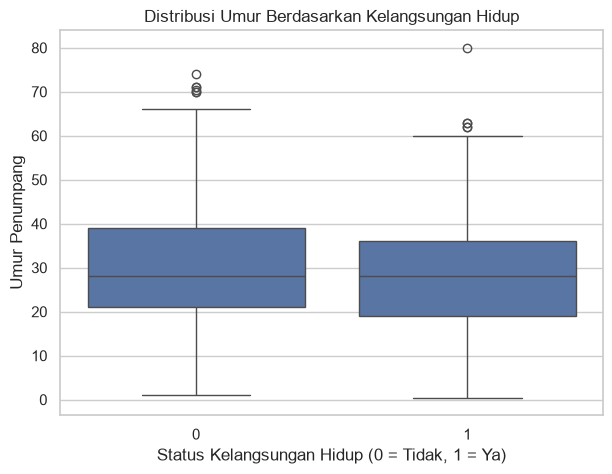

In [14]:
#Cell 11 — Hubungan umur dengan kelangsungan hidup
print("=== Statistik Umur Berdasarkan Kelangsungan Hidup ===")

age_table = df.groupby('Survived')['Age'].agg(
    ['count', 'mean', 'median', 'min', 'max']
)

age_table.index = ['Tidak Selamat', 'Selamat']

display(age_table.round(2))

# Visualisasi
plt.figure(figsize=(7, 5))

sns.boxplot(
    data=df,
    x='Survived',
    y='Age'
)

plt.title('Distribusi Umur Berdasarkan Kelangsungan Hidup')
plt.xlabel('Status Kelangsungan Hidup (0 = Tidak, 1 = Ya)')
plt.ylabel('Umur Penumpang')

plt.show()

=== Statistik Harga Tiket Berdasarkan Kelangsungan Hidup ===


,count,mean,median,min,max
Tidak Selamat,549,22.12,10.5,0.0,263.00
Selamat,342,48.40,26.0,0.0,512.33


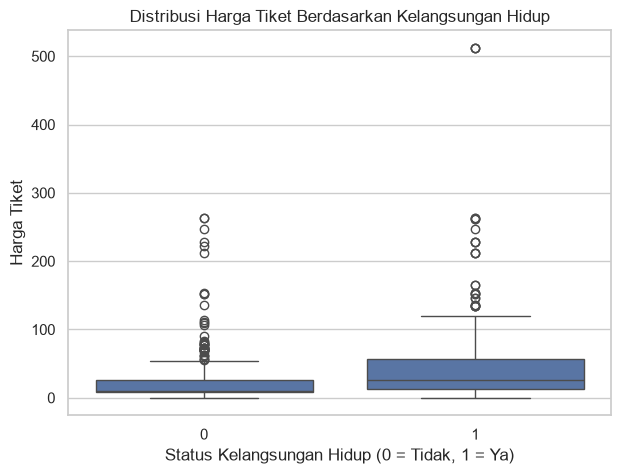

In [15]:
#Cell 12 — Hubungan harga tiket dengan kelangsungan hidup
print("=== Statistik Harga Tiket Berdasarkan Kelangsungan Hidup ===")

fare_table = df.groupby('Survived')['Fare'].agg(
    ['count', 'mean', 'median', 'min', 'max']
)

fare_table.index = ['Tidak Selamat', 'Selamat']

display(fare_table.round(2))

# Visualisasi
plt.figure(figsize=(7, 5))

sns.boxplot(
    data=df,
    x='Survived',
    y='Fare'
)

plt.title('Distribusi Harga Tiket Berdasarkan Kelangsungan Hidup')
plt.xlabel('Status Kelangsungan Hidup (0 = Tidak, 1 = Ya)')
plt.ylabel('Harga Tiket')

plt.show()

=== Pelabuhan Keberangkatan vs Kelangsungan Hidup ===


,Tidak Selamat,Selamat,Total
Embarked,,,
C,75,93,168
Q,47,30,77
S,427,217,644
All,549,340,889


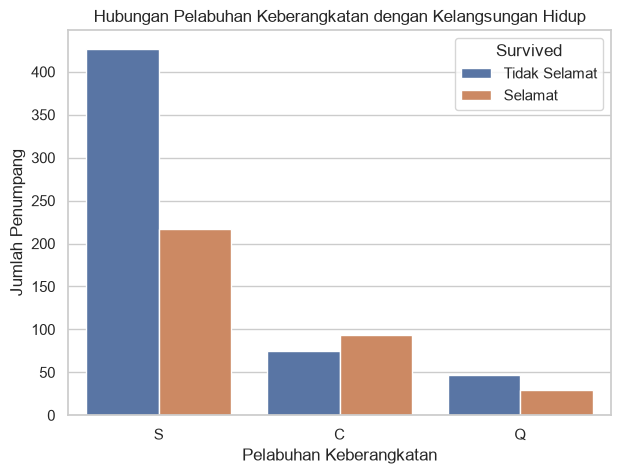

In [16]:
#Cell 13 — Pelabuhan keberangkatan vs kelangsungan hidup
print("=== Pelabuhan Keberangkatan vs Kelangsungan Hidup ===")

embarked_table = pd.crosstab(
    df['Embarked'],
    df['Survived'],
    margins=True
)

embarked_table.columns = ['Tidak Selamat', 'Selamat', 'Total']
display(embarked_table)

# Visualisasi
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x='Embarked',
    hue='Survived'
)

plt.title('Hubungan Pelabuhan Keberangkatan dengan Kelangsungan Hidup')
plt.xlabel('Pelabuhan Keberangkatan')
plt.ylabel('Jumlah Penumpang')
plt.legend(title='Survived', labels=['Tidak Selamat', 'Selamat'])

plt.show()

In [17]:
print("=" * 55)
print("RINGKASAN EXPLORATORY DATA ANALYSIS (EDA)")
print("=" * 55)

print("\n1. INFORMASI DATASET")
print(f"Jumlah data       : {df.shape[0]}")
print(f"Jumlah kolom      : {df.shape[1]}")

print("\n2. DISTRIBUSI TARGET")
print(df['Survived'].value_counts().to_string())

print("\n3. MISSING VALUES")
print(df.isnull().sum().to_string())

print("\n4. JENIS KELAMIN VS SURVIVED")
print(pd.crosstab(df['Sex'], df['Survived']).to_string())

print("\n5. KELAS TIKET VS SURVIVED")
print(pd.crosstab(df['Pclass'], df['Survived']).to_string())

print("\n6. UMUR BERDASARKAN SURVIVED")
print(df.groupby('Survived')['Age'].agg(
    ['count', 'mean', 'median']
).round(2).to_string())

print("\n7. HARGA TIKET BERDASARKAN SURVIVED")
print(df.groupby('Survived')['Fare'].agg(
    ['count', 'mean', 'median']
).round(2).to_string())

print("\n8. PELABUHAN VS SURVIVED")
print(pd.crosstab(df['Embarked'], df['Survived']).to_string())

print("\n" + "=" * 55)
print("EDA SELESAI")
print("=" * 55)

RINGKASAN EXPLORATORY DATA ANALYSIS (EDA)

1. INFORMASI DATASET
Jumlah data       : 891
Jumlah kolom      : 12

2. DISTRIBUSI TARGET
Survived
0    549
1    342

3. MISSING VALUES
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2

4. JENIS KELAMIN VS SURVIVED
Survived    0    1
Sex               
female     81  233
male      468  109

5. KELAS TIKET VS SURVIVED
Survived    0    1
Pclass            
1          80  136
2          97   87
3         372  119

6. UMUR BERDASARKAN SURVIVED
          count   mean  median
Survived                      
0           424  30.63    28.0
1           290  28.34    28.0

7. HARGA TIKET BERDASARKAN SURVIVED
          count   mean  median
Survived                      
0           549  22.12    10.5
1           342  48.40    26.0

8. PELABUHAN VS SURVIVED
Survived    0    1
Emba

In [18]:
#Cell 14 — Menentukan fitur X dan target y
# Menentukan variabel fitur
feature_columns = [
    'Pclass',
    'Sex',
    'Age',
    'SibSp',
    'Parch',
    'Fare',
    'Embarked'
]

X = df[feature_columns].copy()
y = df['Survived'].copy()

print("=== Variabel Fitur (X) ===")
print(X.head().to_string())

print("\n=== Variabel Target (y) ===")
print(y.head().to_string())

print("\nJumlah data fitur:", X.shape)
print("Jumlah data target:", y.shape)

=== Variabel Fitur (X) ===
   Pclass     Sex   Age  SibSp  Parch     Fare Embarked
0       3    male  22.0      1      0   7.2500        S
1       1  female  38.0      1      0  71.2833        C
2       3  female  26.0      0      0   7.9250        S
3       1  female  35.0      1      0  53.1000        S
4       3    male  35.0      0      0   8.0500        S

=== Variabel Target (y) ===
0    0
1    1
2    1
3    1
4    0

Jumlah data fitur: (891, 7)
Jumlah data target: (891,)


In [19]:
#Cell 15 — Membagi data training dan testing
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("=== Pembagian Dataset ===")
print(f"Total data       : {len(X)}")
print(f"Data training    : {len(X_train)}")
print(f"Data testing     : {len(X_test)}")

print("\nDistribusi target data training:")
print(y_train.value_counts().sort_index().to_string())

print("\nDistribusi target data testing:")
print(y_test.value_counts().sort_index().to_string())

=== Pembagian Dataset ===
Total data       : 891
Data training    : 712
Data testing     : 179

Distribusi target data training:
Survived
0    439
1    273

Distribusi target data testing:
Survived
0    110
1     69


In [20]:
#Cell 16 — Mengisi missing values pada Age
# Menghitung median dari data training
age_median = X_train['Age'].median()

# Mengisi nilai kosong pada training dan testing
X_train['Age'] = X_train['Age'].fillna(age_median)
X_test['Age'] = X_test['Age'].fillna(age_median)

print("=== Penanganan Missing Values Age ===")
print(f"Median umur training: {age_median:.2f}")

print("\nMissing values Age setelah preprocessing:")
print(f"Training: {X_train['Age'].isnull().sum()}")
print(f"Testing : {X_test['Age'].isnull().sum()}")

=== Penanganan Missing Values Age ===
Median umur training: 28.50

Missing values Age setelah preprocessing:
Training: 0
Testing : 0


In [21]:
#Cell 17 — Mengisi missing values pada Embarked
# Menghitung modus dari data training
embarked_mode = X_train['Embarked'].mode()[0]

# Mengisi nilai kosong
X_train['Embarked'] = X_train['Embarked'].fillna(embarked_mode)
X_test['Embarked'] = X_test['Embarked'].fillna(embarked_mode)

print("=== Penanganan Missing Values Embarked ===")
print(f"Modus Embarked training: {embarked_mode}")

print("\nMissing values Embarked setelah preprocessing:")
print(f"Training: {X_train['Embarked'].isnull().sum()}")
print(f"Testing : {X_test['Embarked'].isnull().sum()}")

=== Penanganan Missing Values Embarked ===
Modus Embarked training: S

Missing values Embarked setelah preprocessing:
Training: 0
Testing : 0


In [22]:
#Cell 18 — One-Hot Encoding
# Mengubah fitur kategorikal menjadi numerik
X_train = pd.get_dummies(
    X_train,
    columns=['Sex', 'Embarked'],
    dtype=int
)

X_test = pd.get_dummies(
    X_test,
    columns=['Sex', 'Embarked'],
    dtype=int
)

# Menyamakan kolom training dan testing
X_test = X_test.reindex(
    columns=X_train.columns,
    fill_value=0
)

print("=== Hasil One-Hot Encoding ===")
print("Kolom fitur:")
print(X_train.columns.tolist())

print("\nLima data training:")
print(X_train.head().to_string())

print("\nJumlah fitur training:", X_train.shape[1])
print("Jumlah fitur testing :", X_test.shape[1])

=== Hasil One-Hot Encoding ===
Kolom fitur:
['Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'Sex_female', 'Sex_male', 'Embarked_C', 'Embarked_Q', 'Embarked_S']

Lima data training:
     Pclass   Age  SibSp  Parch      Fare  Sex_female  Sex_male  Embarked_C  Embarked_Q  Embarked_S
692       3  28.5      0      0   56.4958           0         1           0           0           1
481       2  28.5      0      0    0.0000           0         1           0           0           1
527       1  28.5      0      0  221.7792           0         1           0           0           1
855       3  18.0      0      1    9.3500           1         0           0           0           1
801       2  31.0      1      1   26.2500           1         0           0           0           1

Jumlah fitur training: 10
Jumlah fitur testing : 10


In [23]:
#Cell 19 — Memeriksa missing values setelah preprocessing
print("=== Missing Values Setelah Preprocessing ===")

missing_train = X_train.isnull().sum()
missing_test = X_test.isnull().sum()

print("\nData Training:")
print(missing_train.to_string())

print("\nData Testing:")
print(missing_test.to_string())

print("\nTotal Missing Values Training:", missing_train.sum())
print("Total Missing Values Testing :", missing_test.sum())

=== Missing Values Setelah Preprocessing ===

Data Training:
Pclass        0
Age           0
SibSp         0
Parch         0
Fare          0
Sex_female    0
Sex_male      0
Embarked_C    0
Embarked_Q    0
Embarked_S    0

Data Testing:
Pclass        0
Age           0
SibSp         0
Parch         0
Fare          0
Sex_female    0
Sex_male      0
Embarked_C    0
Embarked_Q    0
Embarked_S    0

Total Missing Values Training: 0
Total Missing Values Testing : 0


In [24]:
#Cell 20 — Validasi akhir preprocessing
print("=" * 50)
print("VALIDASI HASIL PREPROCESSING")
print("=" * 50)

print("\n1. DIMENSI DATA")
print(f"X_train : {X_train.shape}")
print(f"X_test  : {X_test.shape}")
print(f"y_train : {y_train.shape}")
print(f"y_test  : {y_test.shape}")

print("\n2. TIPE DATA FITUR TRAINING")
print(X_train.dtypes.to_string())

print("\n3. PEMERIKSAAN DATA KOSONG")
print(f"Missing X_train : {X_train.isnull().sum().sum()}")
print(f"Missing X_test  : {X_test.isnull().sum().sum()}")

print("\n4. PEMERIKSAAN TIPE DATA")
print("Semua fitur numerik:",
      all(pd.api.types.is_numeric_dtype(dtype)
          for dtype in X_train.dtypes))

print("\n5. KESESUAIAN KOLOM")
print("Kolom training dan testing sama:",
      list(X_train.columns) == list(X_test.columns))

print("\n" + "=" * 50)
print("PREPROCESSING SELESAI")
print("=" * 50)

VALIDASI HASIL PREPROCESSING

1. DIMENSI DATA
X_train : (712, 10)
X_test  : (179, 10)
y_train : (712,)
y_test  : (179,)

2. TIPE DATA FITUR TRAINING
Pclass          int64
Age           float64
SibSp           int64
Parch           int64
Fare          float64
Sex_female      int64
Sex_male        int64
Embarked_C      int64
Embarked_Q      int64
Embarked_S      int64

3. PEMERIKSAAN DATA KOSONG
Missing X_train : 0
Missing X_test  : 0

4. PEMERIKSAAN TIPE DATA
Semua fitur numerik: True

5. KESESUAIAN KOLOM
Kolom training dan testing sama: True

PREPROCESSING SELESAI


## 3. Pengembangan Model Decision Tree

Pada tahap ini dilakukan pembangunan model klasifikasi menggunakan algoritma Decision Tree Classifier. Pengembangan model dilakukan dengan membuat dua model yang memiliki tingkat kompleksitas berbeda.

1. **Model A (Unpruned Decision Tree):** Model dibuat tanpa pembatasan kedalaman pohon menggunakan parameter `max_depth=None`. Model ini digunakan untuk melihat potensi overfitting.
2. **Model B (Pruned Decision Tree):** Model dibuat dengan membatasi kedalaman pohon menggunakan parameter `max_depth=4`. Pembatasan ini bertujuan mengurangi kompleksitas pohon keputusan agar model dapat melakukan generalisasi dengan lebih baik.

Kedua model dilatih menggunakan data training hasil preprocessing yang sama dan akan dievaluasi menggunakan data testing yang sama.

In [25]:
#Cell 21 — Import dan inisialisasi model
from sklearn.tree import DecisionTreeClassifier

print("Library Decision Tree berhasil diimpor.")

Library Decision Tree berhasil diimpor.


In [26]:
#Cell 22 — Model A (Unpruned Decision Tree)
# Membuat Model A tanpa pruning
model_A = DecisionTreeClassifier(
    max_depth=None,
    random_state=42
)

# Melatih Model A
model_A.fit(X_train, y_train)

print("=== MODEL A: UNPRUNED DECISION TREE ===")
print("Model berhasil dilatih.")
print("Max Depth :", model_A.max_depth)
print("Tree Depth:", model_A.get_depth())
print("Jumlah Node:", model_A.tree_.node_count)
print("Jumlah Leaf:", model_A.get_n_leaves())

=== MODEL A: UNPRUNED DECISION TREE ===
Model berhasil dilatih.
Max Depth : None
Tree Depth: 23
Jumlah Node: 303
Jumlah Leaf: 152


In [27]:
#Cell 23 — Model B (Pruned Decision Tree)
# Membuat Model B dengan pruning
model_B = DecisionTreeClassifier(
    max_depth=4,
    random_state=42
)

# Melatih Model B
model_B.fit(X_train, y_train)

print("=== MODEL B: PRUNED DECISION TREE ===")
print("Model berhasil dilatih.")
print("Max Depth :", model_B.max_depth)
print("Tree Depth:", model_B.get_depth())
print("Jumlah Node:", model_B.tree_.node_count)
print("Jumlah Leaf:", model_B.get_n_leaves())

=== MODEL B: PRUNED DECISION TREE ===
Model berhasil dilatih.
Max Depth : 4
Tree Depth: 4
Jumlah Node: 29
Jumlah Leaf: 15


In [28]:
#Cell 24 — Ringkasan kedua model
print("=" * 55)
print("RINGKASAN MODEL DECISION TREE")
print("=" * 55)

models = {
    "Model A (Unpruned)": model_A,
    "Model B (Pruned)": model_B
}

for name, model in models.items():
    print(f"\n{name}")
    print("-" * 40)
    print(f"Max Depth       : {model.max_depth}")
    print(f"Actual Depth    : {model.get_depth()}")
    print(f"Jumlah Node     : {model.tree_.node_count}")
    print(f"Jumlah Leaf     : {model.get_n_leaves()}")

print("\n" + "=" * 55)
print("KEDUA MODEL BERHASIL DILATIH")
print("=" * 55)

RINGKASAN MODEL DECISION TREE

Model A (Unpruned)
----------------------------------------
Max Depth       : None
Actual Depth    : 23
Jumlah Node     : 303
Jumlah Leaf     : 152

Model B (Pruned)
----------------------------------------
Max Depth       : 4
Actual Depth    : 4
Jumlah Node     : 29
Jumlah Leaf     : 15

KEDUA MODEL BERHASIL DILATIH


## Tahap 4 — Evaluasi dan Perbandingan Model
Tujuan
Sesuai instruksi dosen, kita akan:
1. Melakukan prediksi menggunakan kedua model.
2. Menampilkan classification_report.
3. Menampilkan confusion_matrix.
4. Membandingkan akurasi training dan testing.
5. Menganalisis apakah terjadi overfitting.

In [29]:
#Cell 25 — Import library evaluasi
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

print("Library evaluasi berhasil diimpor.")

Library evaluasi berhasil diimpor.


In [30]:
#Cell 26 — Melakukan prediksi kedua model
# Prediksi Model A
y_pred_A = model_A.predict(X_test)

# Prediksi Model B
y_pred_B = model_B.predict(X_test)

print("=== HASIL PREDIKSI ===")
print("Model A:", len(y_pred_A), "data berhasil diprediksi")
print("Model B:", len(y_pred_B), "data berhasil diprediksi")

print("\nLima hasil prediksi Model A:")
print(y_pred_A[:5])

print("\nLima hasil prediksi Model B:")
print(y_pred_B[:5])

print("\nLima label sebenarnya:")
print(y_test.iloc[:5].values)

=== HASIL PREDIKSI ===
Model A: 179 data berhasil diprediksi
Model B: 179 data berhasil diprediksi

Lima hasil prediksi Model A:
[0 0 0 0 1]

Lima hasil prediksi Model B:
[0 0 0 0 1]

Lima label sebenarnya:
[0 0 1 0 1]


In [31]:
#Cell 27 — Classification Report
print("=" * 60)
print("CLASSIFICATION REPORT - MODEL A (UNPRUNED)")
print("=" * 60)

print(classification_report(
    y_test,
    y_pred_A,
    target_names=['Tidak Selamat', 'Selamat'],
    digits=4
))

print("=" * 60)
print("CLASSIFICATION REPORT - MODEL B (PRUNED)")
print("=" * 60)

print(classification_report(
    y_test,
    y_pred_B,
    target_names=['Tidak Selamat', 'Selamat'],
    digits=4
))

CLASSIFICATION REPORT - MODEL A (UNPRUNED)
               precision    recall  f1-score   support

Tidak Selamat     0.8376    0.8909    0.8634       110
      Selamat     0.8065    0.7246    0.7634        69

     accuracy                         0.8268       179
    macro avg     0.8220    0.8078    0.8134       179
 weighted avg     0.8256    0.8268    0.8249       179

CLASSIFICATION REPORT - MODEL B (PRUNED)
               precision    recall  f1-score   support

Tidak Selamat     0.7704    0.9455    0.8490       110
      Selamat     0.8636    0.5507    0.6726        69

     accuracy                         0.7933       179
    macro avg     0.8170    0.7481    0.7608       179
 weighted avg     0.8063    0.7933    0.7810       179



=== CONFUSION MATRIX MODEL A ===
[[98 12]
 [19 50]]

=== CONFUSION MATRIX MODEL B ===
[[104   6]
 [ 31  38]]


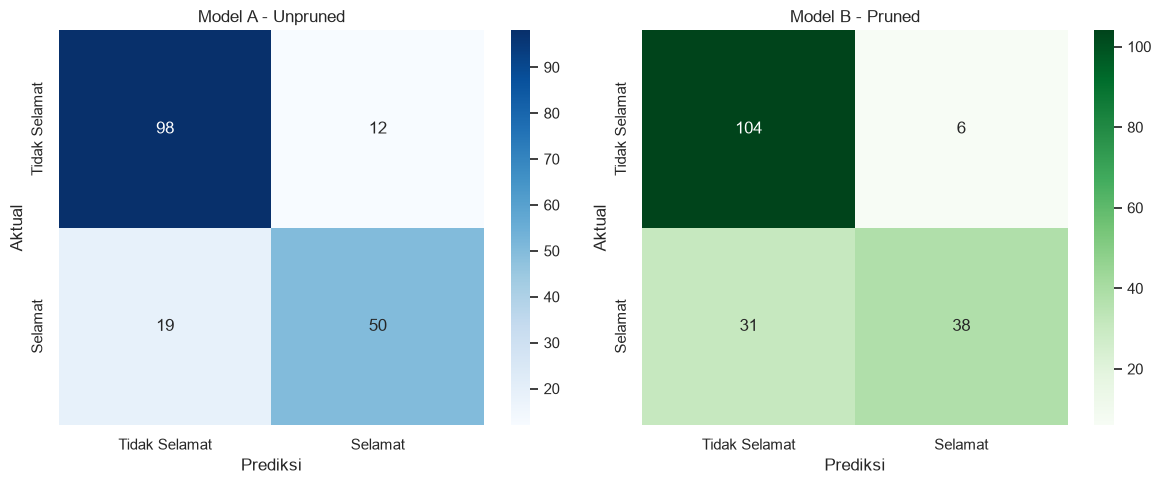

In [32]:
#Cell 28 — Confusion Matrix
# Menghitung confusion matrix
cm_A = confusion_matrix(y_test, y_pred_A)
cm_B = confusion_matrix(y_test, y_pred_B)

print("=== CONFUSION MATRIX MODEL A ===")
print(cm_A)

print("\n=== CONFUSION MATRIX MODEL B ===")
print(cm_B)

# Visualisasi kedua confusion matrix
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.heatmap(
    cm_A,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Tidak Selamat', 'Selamat'],
    yticklabels=['Tidak Selamat', 'Selamat'],
    ax=axes[0]
)

axes[0].set_title('Model A - Unpruned')
axes[0].set_xlabel('Prediksi')
axes[0].set_ylabel('Aktual')

sns.heatmap(
    cm_B,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=['Tidak Selamat', 'Selamat'],
    yticklabels=['Tidak Selamat', 'Selamat'],
    ax=axes[1]
)

axes[1].set_title('Model B - Pruned')
axes[1].set_xlabel('Prediksi')
axes[1].set_ylabel('Aktual')

plt.tight_layout()
plt.show()

In [33]:
#Cell 29 — Menghitung akurasi Training dan Testing
# Prediksi pada data training
train_pred_A = model_A.predict(X_train)
train_pred_B = model_B.predict(X_train)

# Akurasi Model A
train_acc_A = accuracy_score(y_train, train_pred_A)
test_acc_A = accuracy_score(y_test, y_pred_A)

# Akurasi Model B
train_acc_B = accuracy_score(y_train, train_pred_B)
test_acc_B = accuracy_score(y_test, y_pred_B)

print("=" * 60)
print("PERBANDINGAN AKURASI TRAINING DAN TESTING")
print("=" * 60)

print("\nMODEL A - UNPRUNED")
print(f"Akurasi Training : {train_acc_A:.4f} ({train_acc_A*100:.2f}%)")
print(f"Akurasi Testing  : {test_acc_A:.4f} ({test_acc_A*100:.2f}%)")

print("\nMODEL B - PRUNED")
print(f"Akurasi Training : {train_acc_B:.4f} ({train_acc_B*100:.2f}%)")
print(f"Akurasi Testing  : {test_acc_B:.4f} ({test_acc_B*100:.2f}%)")

PERBANDINGAN AKURASI TRAINING DAN TESTING

MODEL A - UNPRUNED
Akurasi Training : 0.9831 (98.31%)
Akurasi Testing  : 0.8268 (82.68%)

MODEL B - PRUNED
Akurasi Training : 0.8413 (84.13%)
Akurasi Testing  : 0.7933 (79.33%)


In [34]:
#Cell 30 — Tabel perbandingan kedua model
comparison = pd.DataFrame({
    'Model': ['Model A (Unpruned)', 'Model B (Pruned)'],
    'Training Accuracy': [train_acc_A, train_acc_B],
    'Testing Accuracy': [test_acc_A, test_acc_B],
    'Selisih Akurasi': [
        train_acc_A - test_acc_A,
        train_acc_B - test_acc_B
    ],
    'Tree Depth': [
        model_A.get_depth(),
        model_B.get_depth()
    ],
    'Jumlah Node': [
        model_A.tree_.node_count,
        model_B.tree_.node_count
    ],
    'Jumlah Leaf': [
        model_A.get_n_leaves(),
        model_B.get_n_leaves()
    ]
})

print("=== TABEL PERBANDINGAN MODEL ===")
display(comparison.round(4))

print("\n=== RINGKASAN DALAM TEKS ===")
print(comparison.to_string(index=False))

=== TABEL PERBANDINGAN MODEL ===


,Model,Training Accuracy,Testing Accuracy,Selisih Akurasi,Tree Depth,Jumlah Node,Jumlah Leaf
0,Model A (Unpruned),0.9831,0.8268,0.1563,23,303,152
1,Model B (Pruned),0.8413,0.7933,0.0480,4,29,15



=== RINGKASAN DALAM TEKS ===
             Model  Training Accuracy  Testing Accuracy  Selisih Akurasi  Tree Depth  Jumlah Node  Jumlah Leaf
Model A (Unpruned)           0.983146          0.826816         0.156330          23          303          152
  Model B (Pruned)           0.841292          0.793296         0.047996           4           29           15


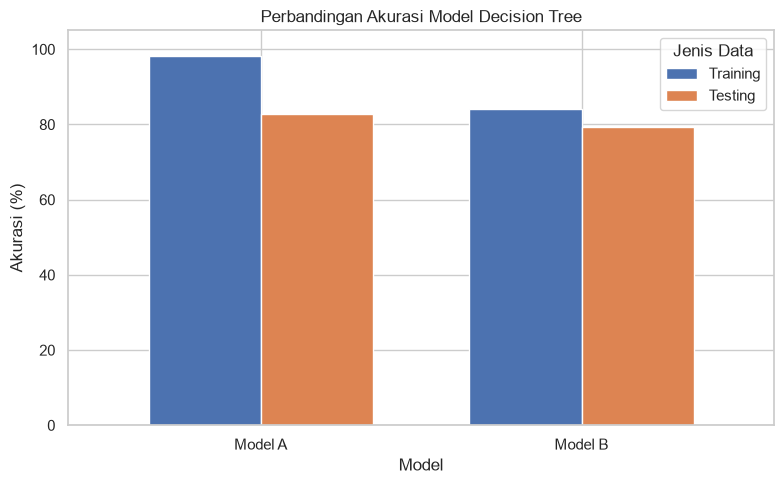

=== DATA AKURASI UNTUK PERBANDINGAN ===
  Model  Training   Testing
Model A 98.314607 82.681564
Model B 84.129213 79.329609


In [35]:
#Cell 31 — Visualisasi perbandingan akurasi
accuracy_comparison = pd.DataFrame({
    'Model': ['Model A', 'Model B'],
    'Training': [train_acc_A * 100, train_acc_B * 100],
    'Testing': [test_acc_A * 100, test_acc_B * 100]
})

accuracy_comparison.plot(
    x='Model',
    kind='bar',
    figsize=(8, 5),
    width=0.7
)

plt.title('Perbandingan Akurasi Model Decision Tree')
plt.xlabel('Model')
plt.ylabel('Akurasi (%)')
plt.ylim(0, 105)
plt.xticks(rotation=0)
plt.legend(title='Jenis Data')
plt.tight_layout()
plt.show()

print("=== DATA AKURASI UNTUK PERBANDINGAN ===")
print(accuracy_comparison.to_string(index=False))

## Tahap 5 — Visualisasi dan Interpretasi Decision Tree

Tahap ini dilakukan untuk memahami struktur model Decision Tree yang telah dilatih. Visualisasi digunakan untuk melihat proses pengambilan keputusan, sedangkan Feature Importance digunakan untuk mengetahui fitur yang paling berpengaruh terhadap prediksi kelangsungan hidup penumpang Titanic.